# Wine Dataset - A Small EDA Project

In this notebook, I am trying to understand the Wine dataset using Python.

I will first look at the data, check if anything is missing, and then make a few graphs. I also want to see whether the three wine classes have different measurements.

I am still learning pandas and data visualization, so I have kept the analysis simple.

**Dataset:** `wine_data.csv`  
**Libraries:** pandas, NumPy, Matplotlib and Seaborn

## 1. Importing the libraries

I will use pandas to work with the table, NumPy for numerical operations, and Matplotlib and Seaborn for graphs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## 2. Reading the CSV file

I have kept the CSV file in the same folder as this notebook. If the file is somewhere else, the path below will need to be changed.

In [2]:
df = pd.read_csv("wine_data.csv")
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,class_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


## 3. Getting familiar with the data

First I want to know how many rows and columns there are. I am also checking the column names and data types.

In [3]:
print("Rows and columns:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
df.info()

Rows and columns: (178, 15)
\nColumn names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target', 'class_name']
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178

The `head()` function showed me a few rows. Now I am checking summary values like the average, minimum and maximum.

In [4]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


## 4. Checking missing values and duplicates

Before making graphs, I want to check whether some values are missing or whether any complete rows are repeated.

In [5]:
print("Missing values in each column:")
print(df.isna().sum())
print("\\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values in each column:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
class_name                      0
dtype: int64
\nNumber of duplicate rows:
0


## 5. Looking at the wine classes

The `class_name` column tells us which of the three groups each wine sample belongs to. I am counting the samples in each group.

class_name
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


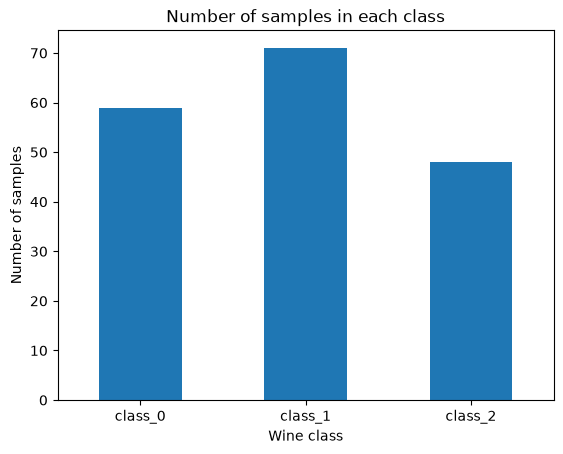

In [6]:
class_counts = df["class_name"].value_counts().sort_index()
print(class_counts)

class_counts.plot(kind="bar", title="Number of samples in each class")
plt.xlabel("Wine class")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.show()

## 6. Looking at individual columns

A histogram helps me see where most of the values are concentrated. I am plotting the numerical columns together to get an overall idea of their distributions.

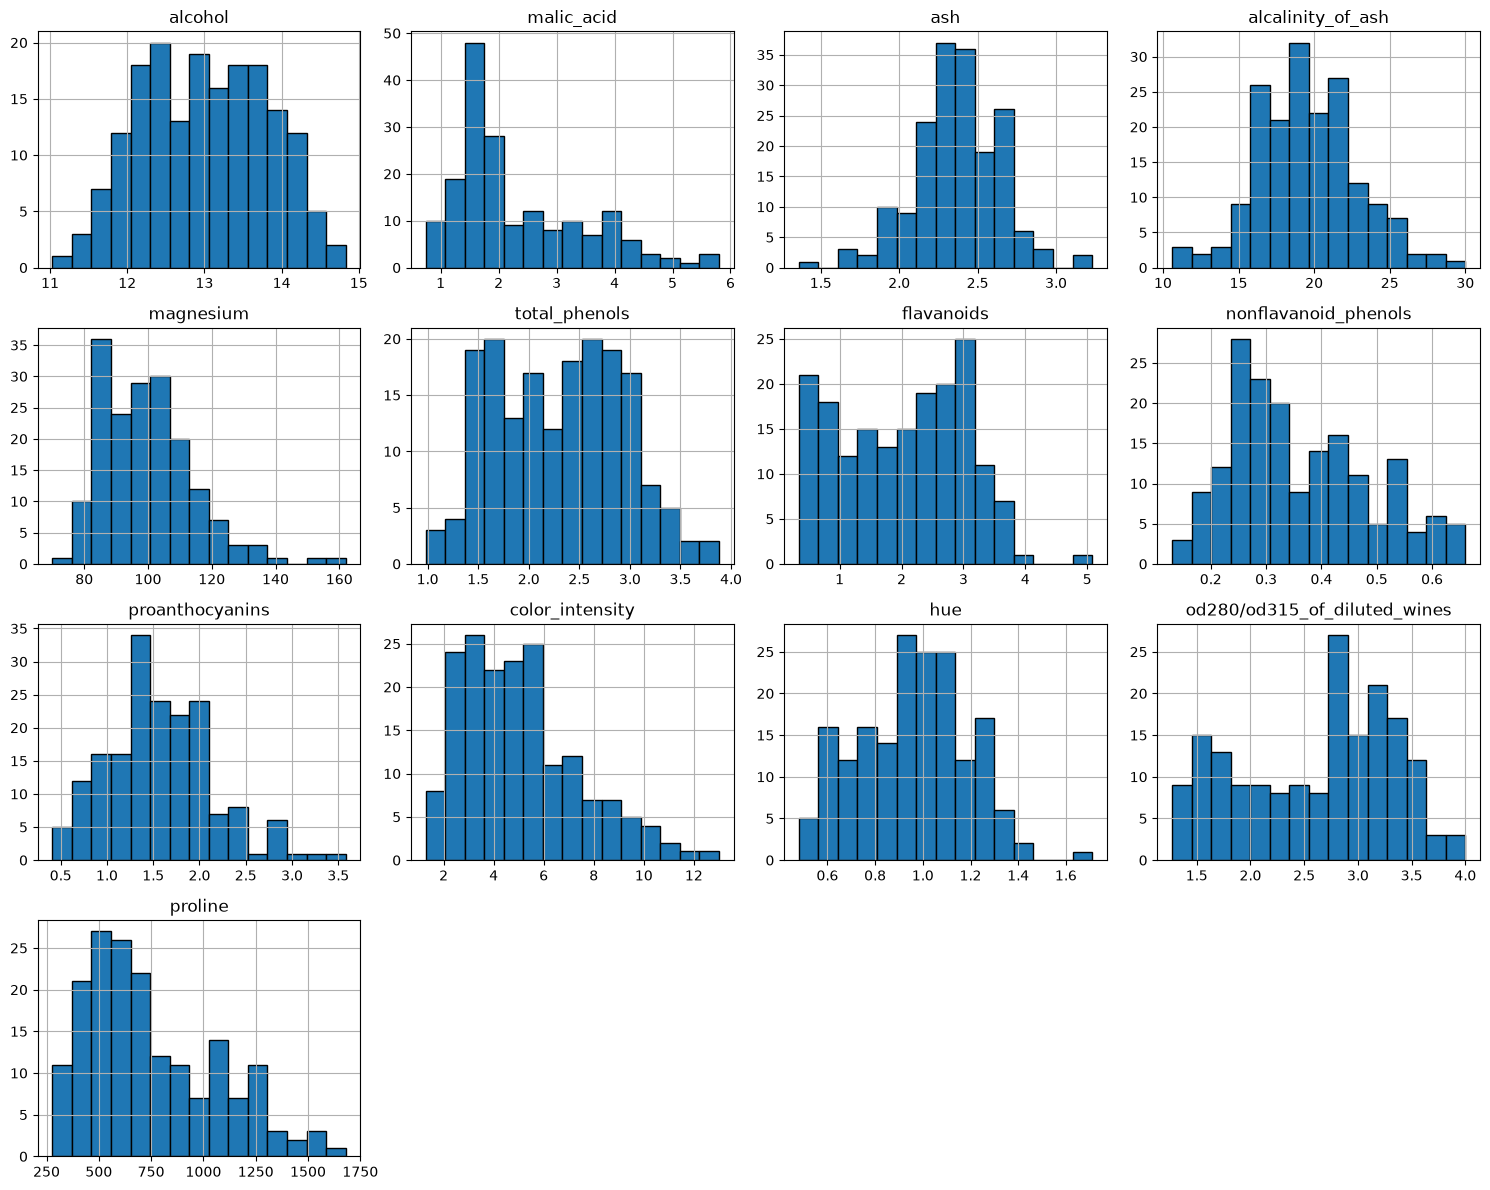

In [7]:
features = df.select_dtypes(include="number").columns.drop("target")
df[features].hist(figsize=(15, 12), bins=15, edgecolor="black")
plt.tight_layout()
plt.show()

From these histograms, I can compare the shapes of the columns. Some look more spread out than others. The scales are also different, so the axes should be read separately.

## 7. Checking possible outliers

I am using boxplots to get an idea of values that are far away from the middle part of a column. A point outside the whiskers is only a possible outlier; it does not automatically mean the value is wrong.

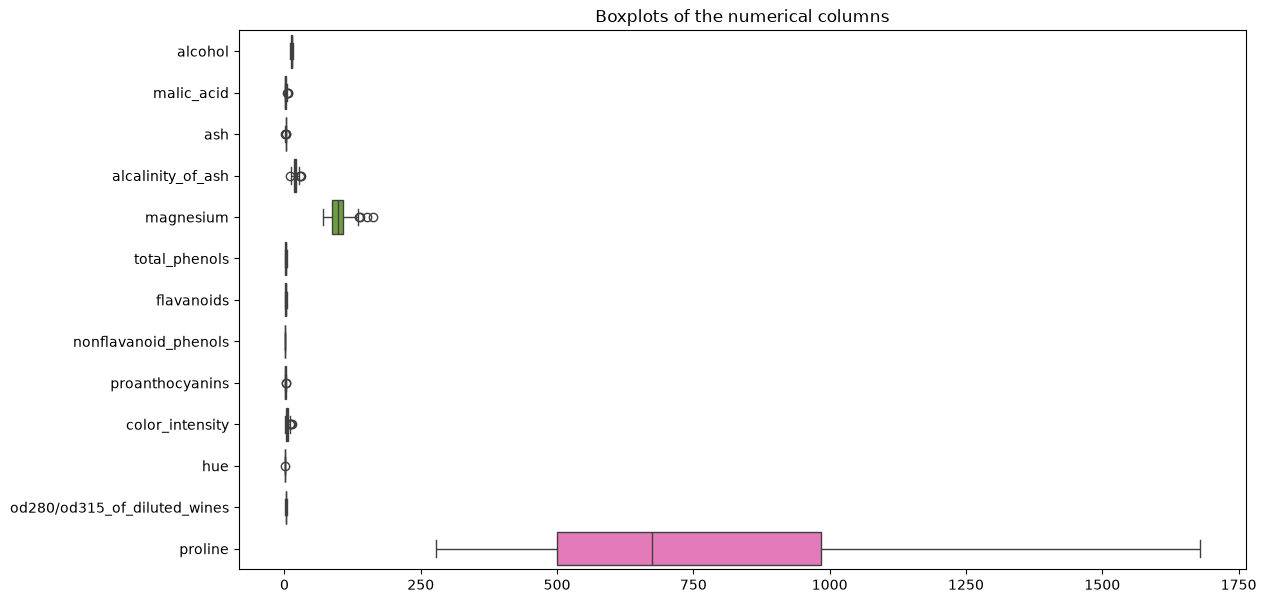

In [8]:
plt.figure(figsize=(13, 7))
sns.boxplot(data=df[features], orient="h")
plt.title("Boxplots of the numerical columns")
plt.show()

I can also count values outside the usual IQR limits. The limits are calculated separately for every column.

In [9]:
outlier_counts = {}

for col in features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    count = ((df[col] < lower_limit) | (df[col] > upper_limit)).sum()
    outlier_counts[col] = count

pd.Series(outlier_counts, name="Possible outliers").sort_values(ascending=False)

magnesium                       4
alcalinity_of_ash               4
color_intensity                 4
malic_acid                      3
ash                             3
proanthocyanins                 2
hue                             1
alcohol                         0
total_phenols                   0
nonflavanoid_phenols            0
flavanoids                      0
od280/od315_of_diluted_wines    0
proline                         0
Name: Possible outliers, dtype: int64

## 8. Checking correlation between columns

I want to see which numerical columns move together. I am using Pearson correlation here. A positive value means the two columns tend to increase together, while a negative value means one tends to decrease when the other increases.

Correlation does not mean that one column causes the other to change.

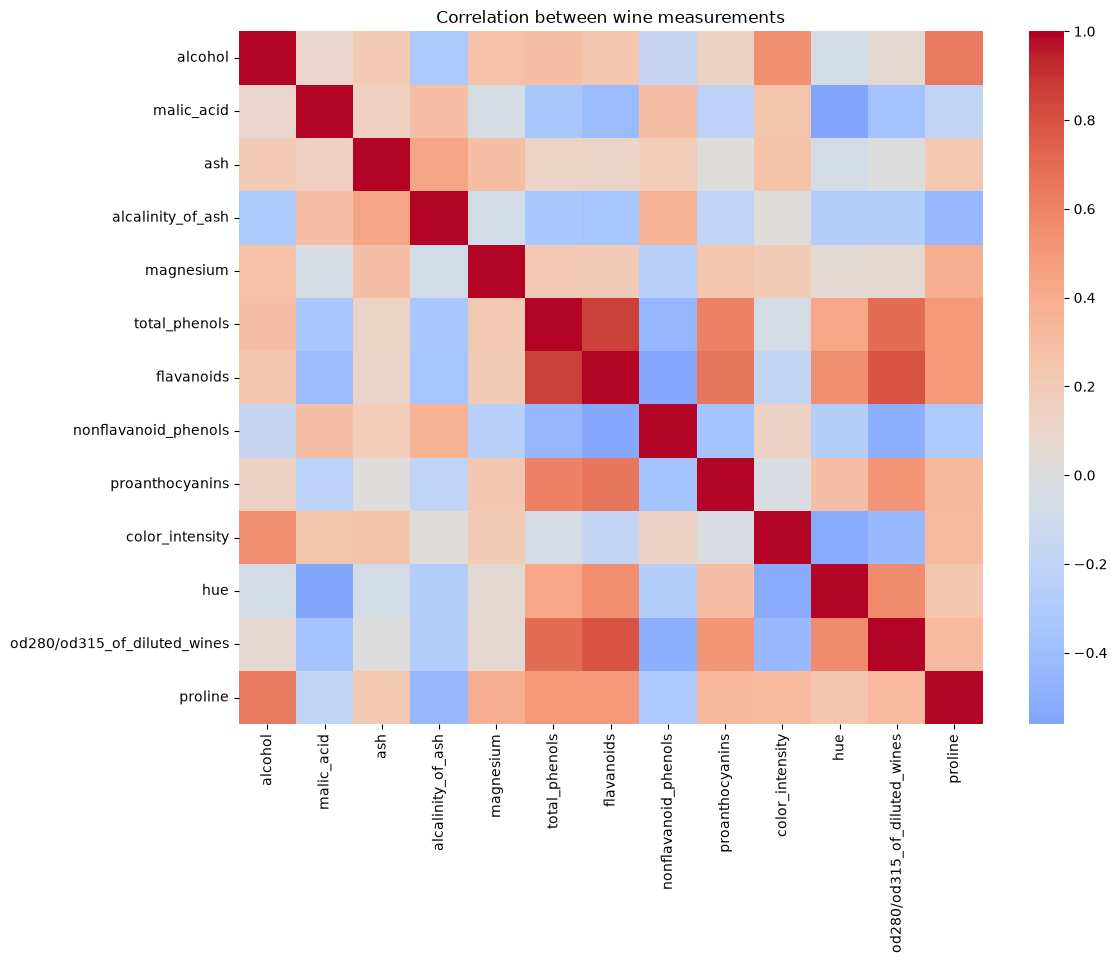

In [10]:
corr = df[features].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation between wine measurements")
plt.show()

I will also print the strongest pairs so that I do not have to inspect every cell of the heatmap manually.

In [11]:
upper_triangle = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong_pairs = upper_triangle.stack().sort_values(
    key=lambda values: values.abs(),
    ascending=False
)
strong_pairs.head(10)

total_phenols  flavanoids                      0.864564
flavanoids     od280/od315_of_diluted_wines    0.787194
total_phenols  od280/od315_of_diluted_wines    0.699949
flavanoids     proanthocyanins                 0.652692
alcohol        proline                         0.643720
total_phenols  proanthocyanins                 0.612413
hue            od280/od315_of_diluted_wines    0.565468
malic_acid     hue                            -0.561296
alcohol        color_intensity                 0.546364
flavanoids     hue                             0.543479
dtype: float64

## 9. Comparing the classes

Now I am comparing the average values of a few columns for each class. This may help me notice which measurements are different between the groups.

In [12]:
selected_columns = ["alcohol", "flavanoids", "color_intensity", "proline"]
df.groupby("class_name")[selected_columns].mean().round(2)

,alcohol,flavanoids,color_intensity,proline
class_name,,,,
class_0,13.74,2.98,5.53,1115.71
class_1,12.28,2.08,3.09,519.51
class_2,13.15,0.78,7.40,629.90


I have made boxplots for the same columns so that I can compare not only the averages but also the spread of values.

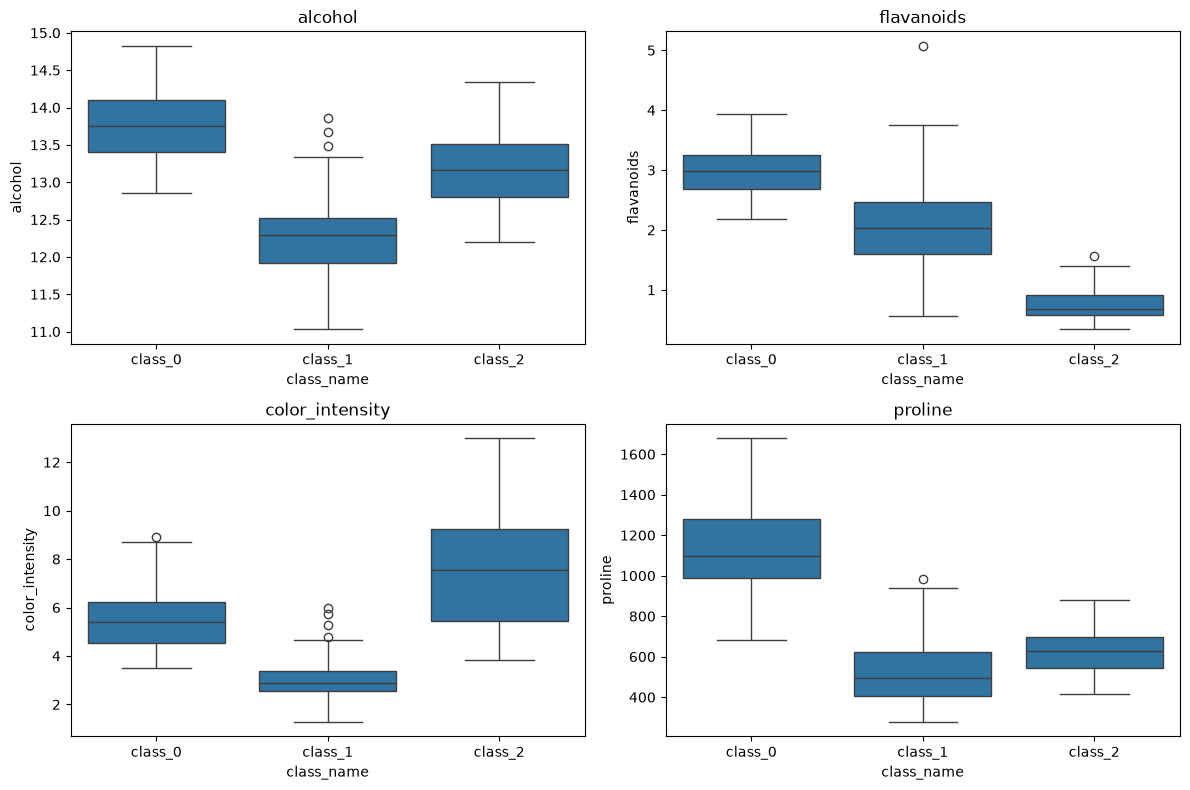

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, ax in zip(selected_columns, axes.flatten()):
    sns.boxplot(data=df, x="class_name", y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## 10. Looking at a few columns together

A pair plot makes scatter plots for pairs of columns. I am using only a few columns because plotting all of them would make the figure crowded.

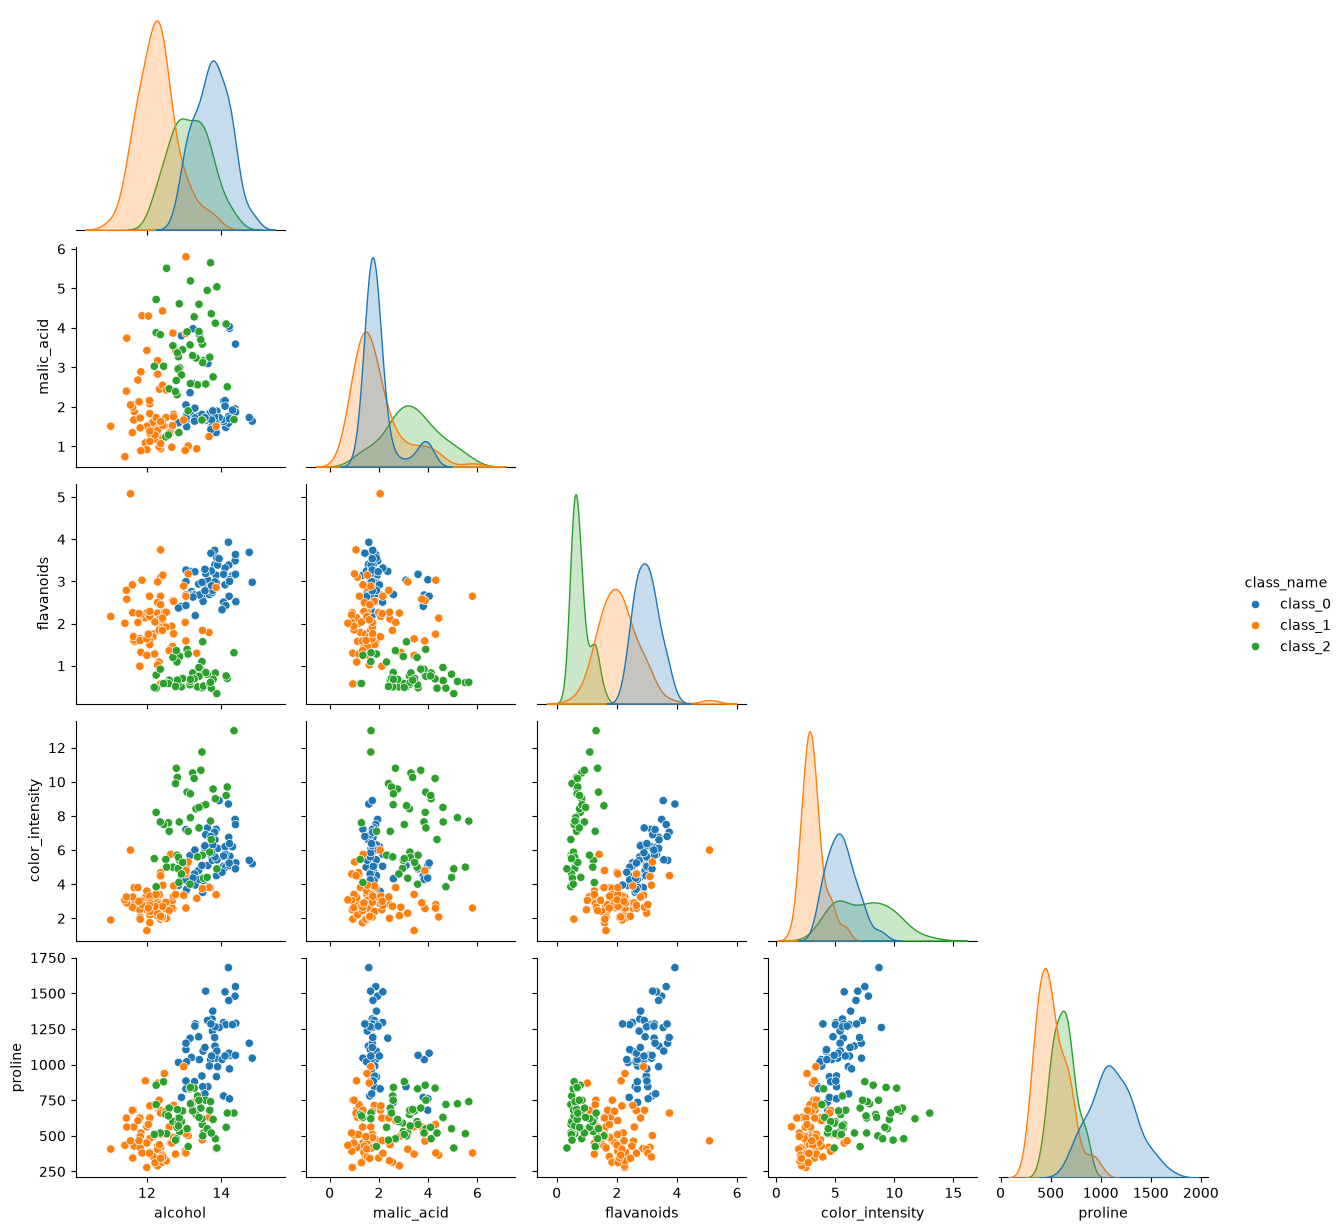

In [14]:
sns.pairplot(
    df[["alcohol", "malic_acid", "flavanoids", "color_intensity", "proline", "class_name"]],
    hue="class_name",
    corner=True
)
plt.show()

## 11. What I noticed

After looking at the tables and graphs, these are some points I noticed:

- The dataset has 178 rows and 13 numerical measurement columns, along with the target and class name.
- The dataset has three wine classes.
- I did not find missing values or exact duplicate rows in this CSV.
- The class counts are not exactly the same.
- Total phenols and flavanoids have a strong positive correlation in this dataset.
- The average values of some measurements are different across the three classes.

These are observations from this dataset only. They do not prove that one measurement causes another, and I have not trained a machine learning model in this notebook.

## 12. Conclusion

This was my first exploratory data analysis project. I used pandas to inspect and summarize the data, and Matplotlib and Seaborn to make graphs.

I learned how to check missing values and duplicates, look at distributions, identify possible outliers, calculate correlations and compare groups.

The next thing I can try is using these features to train a classification model. I will keep that as a separate project so that I can learn the machine learning steps properly.